# In this notebook we calculate different brezier curves and check their radius

In [1]:
import numpy as np
from scipy.special import comb
import math

def bernstein_poly(i, n, t):
    """
     The Bernstein polynomial of n, i as a function of t
    """

    # return comb(n, i) * ( t**(n-i) ) * (1 - t)**i
    return comb(n, i) * (1 - t)**(n-i) * (t**i)


def bezier_curve(points, nTimes=1000):
    """
       Given a set of control points, return the
       bezier curve defined by the control points.

       points should be a list of lists, or list of tuples
       such as [ [1,1], 
                 [2,3], 
                 [4,5], ..[Xn, Yn] ]
        nTimes is the number of time steps, defaults to 1000

        See http://processingjs.nihongoresources.com/bezierinfo/
    """

    nPoints = len(points)
    xPoints = np.array([p[0] for p in points])
    yPoints = np.array([p[1] for p in points])

    t = np.linspace(0.0, 1.0, nTimes)

    polynomial_array = np.array([ bernstein_poly(i, nPoints-1, t) for i in range(0, nPoints)   ])

    xvals = np.dot(xPoints, polynomial_array)
    yvals = np.dot(yPoints, polynomial_array)

    return xvals, yvals


def radius(xvals, yvals, nTimes=1000):
    orig = (0,0)
    mid = int(nTimes/2)
    quart = int(mid/2)
    min_rad = math.dist(orig,
                        (0, yvals[0]))
    quart_rad = math.dist(orig,
                        (xvals[quart], yvals[quart]))
    max_rad = math.dist(orig,
                        (xvals[mid], yvals[mid]))
    
    return min_rad, quart_rad, max_rad

<>:45: SyntaxWarning: invalid escape sequence '\m'
<>:48: SyntaxWarning: invalid escape sequence '\m'
<>:45: SyntaxWarning: invalid escape sequence '\m'
<>:48: SyntaxWarning: invalid escape sequence '\m'
C:\TEMP\ipykernel_15704\2159061686.py:45: SyntaxWarning: invalid escape sequence '\m'
  plt.text(xvals[r]*2/3, yvals[r]/2, "{:.2f} $\mu$m".format(radius(xvals, yvals)[idx]))
C:\TEMP\ipykernel_15704\2159061686.py:48: SyntaxWarning: invalid escape sequence '\m'
  plt.title("w=30 $\mu$m, ID: "+str(id))


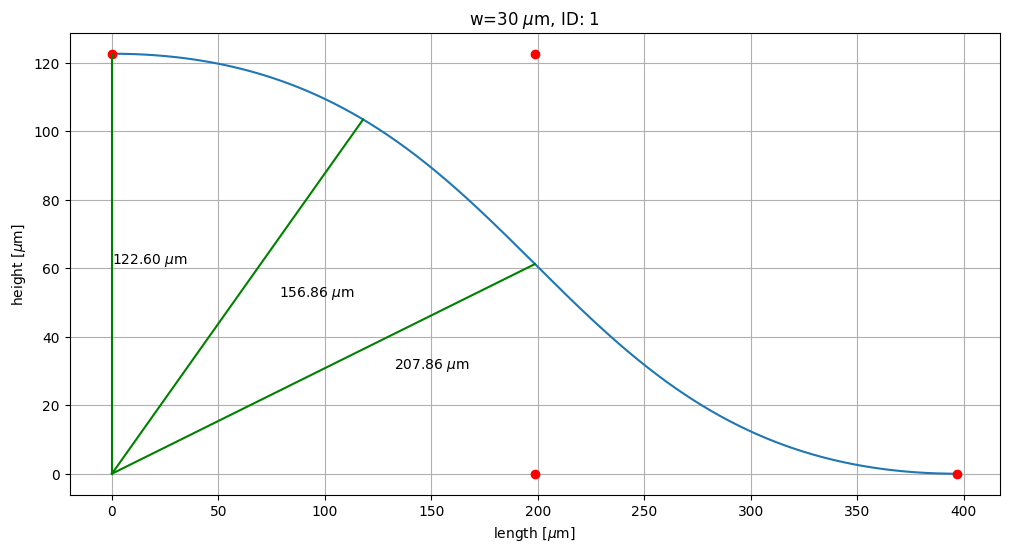

In [2]:
from matplotlib import pyplot as plt

s_bend_height = 122.6
s_bend_length = 397
id = 1
name = "simulations/Amina_special/s_bends/Amina-Nassim_bend_"+str(id)
# p_1 = 7500  # 7500
# p_2 = 7500  #7500

# nPoints = 6
# d = 235.9
# b = 100 * 4/3 * (np.sqrt(2) - 1)
# points = [
#     (0,                 s_bend_height),
#     (b,                 s_bend_height),
#     (s_bend_length/2,   s_bend_height/2 +b),
#     (s_bend_length/2,   s_bend_height/2 -b),
#     (s_bend_length-b,   0),
#     (s_bend_length,     0)
# ]
# xpoints = [p[0] for p in points]
# ypoints = [p[1] for p in points]
nPoints = 4
d = s_bend_length
b = 100 * 4/3 * (np.sqrt(2) - 1)
points = [
    (0,                 s_bend_height),
    (s_bend_length/2,   s_bend_height),
    (s_bend_length/2,   0),
    (s_bend_length,     0)
]
xpoints = [p[0] for p in points]
ypoints = [p[1] for p in points]

xvals, yvals = bezier_curve(points, nTimes=1000)

plt.figure(figsize=(12,6))
plt.plot(xvals, yvals)
plt.plot(xpoints, ypoints, "ro")

rads = radius(xvals, yvals)
idx=0
for r in [0,250,500]:
    plt.plot([0,xvals[r]],[0,yvals[r]], 'green')
    plt.text(xvals[r]*2/3, yvals[r]/2, "{:.2f} $\mu$m".format(radius(xvals, yvals)[idx]))
    idx += 1

plt.title("w=30 $\mu$m, ID: "+str(id))
plt.ylabel(r"height [$\mu$m]")
plt.xlabel(r"length [$\mu$m]")
plt.grid(True)

# plt.savefig(name)

# Building in Ansys and exporting to GDSII

In [3]:
import optics_simulator as sim

In [4]:
# base_height = 500       # Silicon base' height
insul_height_bot = 3    # insulation below lower waveguide
insul_height_top = 3    # insulation above upper waveguide

wg_material = "Si3N4 (Silicon Nitride) - Luke"
cover_material = "SiO2 (Glass) - Palik"

lower_wg_height = 0.075
upper_wg_height = 0.175
base_angle = 82             # previously was 82°; below 72° doesn't work
upper_wg_top_width = 1.1    # um
triplex_dist = 0.1          # the insulation between the two layer of waveguides

coupling_length = 77.43   # length of the coupling region
coupling_gap = 1        # the gap between modes in the coupling region (in `y` direction)


geometries = sim.GeometryHolder(lower_wg_height,upper_wg_height,upper_wg_top_width,
            base_angle,triplex_dist,s_bend_height,s_bend_length,coupling_gap,
            coupling_length,wg_material,cover_material)

dist_gap = triplex_dist + geometries.lower_wg["base height"]/2 + geometries.upper_wg["base height"]/2
dist_gap = dist_gap*1e-6

structure: dict = {
    geometries.lower_wg["base height"] : geometries.lower_wg['material'],
    triplex_dist + geometries.lower_wg["base height"]/2 + geometries.upper_wg["base height"] - 1e-4: geometries.upper_wg['material']
}

# poles = "["+str(points[0][0])+","+str(points[0][1])+";"\
#         +str(points[1][0])+","+str(points[1][1])+";"\
#         +str(points[2][0])+","+str(points[2][1])+";"\
#         +str(points[3][0])+","+str(points[3][1])+";"\
#         +str(points[4][0])+","+str(points[4][1])+";"\
#         +str(points[5][0])+","+str(points[5][1])+"]"
poles = "["+str(xpoints[0])+","+str(ypoints[0])+";"\
        +str(xpoints[1])+","+str(ypoints[1])+";"\
        +str(xpoints[2])+","+str(ypoints[2])+";"\
        +str(xpoints[3])+","+str(ypoints[3])+"]"

In [5]:
s_bend_top = sim.BentWGD(geometries.upper_wg['base width'],
                        geometries.upper_wg['base height'],
                        geometries.upper_wg['base angle'],
                        geometries.upper_wg['material'],
                        poles).builder("S-bend_top")

s_bend_bot = sim.BentWGD(geometries.lower_wg['base width'],
                        geometries.lower_wg['base height'],
                        geometries.lower_wg['base angle'],
                        geometries.lower_wg['material'],
                        poles).builder("S-bend_bot")

print(s_bend_top)
print(s_bend_bot)

addwaveguide;
set("base width", 1.149189292145837* 1e-6);
set("base height", 0.175* 1e-6);
set("base angle", 82);
set("poles", [0,122.6;198.5,122.6;198.5,0;397,0] * 1e-6);
set("material", "Si3N4 (Silicon Nitride) - Luke");
set("override mesh order from material database",1);
set("mesh order",1);
set('name','S-bend_top');

addwaveguide;
set("base width", 1.198378584291674* 1e-6);
set("base height", 0.075* 1e-6);
set("base angle", 82);
set("poles", [0,122.6;198.5,122.6;198.5,0;397,0] * 1e-6);
set("material", "Si3N4 (Silicon Nitride) - Luke");
set("override mesh order from material database",1);
set("mesh order",1);
set('name','S-bend_bot');



In [6]:
script = "addstructuregroup;\n"\
        + "set('name','upper_wg');\n"\
        + s_bend_top\
        + "set(\"base width\", "+str(geometries.upper_wg['base width'])+"*1e-6);\n"\
        + "addtogroup('upper_wg');\n"\
        + "addstructuregroup;\n"\
        + "set('name','lower_wg');\n"\
        + s_bend_bot\
        + "set(\"base width\", "+str(geometries.lower_wg['base width'])+"*1e-6);\n"\
        + "addtogroup('lower_wg');\n"\

script += "select('upper_wg');\n"\
            +"set(\"z\", "+str(dist_gap)+");\n"\

script += sim.layout(bot_wg_height=lower_wg_height,
                    top_wg_height=upper_wg_height,
                    dist=triplex_dist,
                    wg_material=wg_material,
                    path="D:/Interferometer/gds_auto_export_package/gds_auto_export_package",
                    name=name)

print(script)

addstructuregroup;
set('name','upper_wg');
addwaveguide;
set("base width", 1.149189292145837* 1e-6);
set("base height", 0.175* 1e-6);
set("base angle", 82);
set("poles", [0,122.6;198.5,122.6;198.5,0;397,0] * 1e-6);
set("material", "Si3N4 (Silicon Nitride) - Luke");
set("override mesh order from material database",1);
set("mesh order",1);
set('name','S-bend_top');
set("base width", 1.149189292145837*1e-6);
addtogroup('upper_wg');
addstructuregroup;
set('name','lower_wg');
addwaveguide;
set("base width", 1.198378584291674* 1e-6);
set("base height", 0.075* 1e-6);
set("base angle", 82);
set("poles", [0,122.6;198.5,122.6;198.5,0;397,0] * 1e-6);
set("material", "Si3N4 (Silicon Nitride) - Luke");
set("override mesh order from material database",1);
set("mesh order",1);
set('name','S-bend_bot');
set("base width", 1.198378584291674*1e-6);
addtogroup('lower_wg');
select('upper_wg');
set("z", 2.25e-07);
feval('D:/Interferometer/gds_auto_export_package/gds_auto_export_package/GDSexport_core.lsfx')

In [7]:
mode = sim.mode_select("FDTD", vis=True)

mode.eval(script)
mode.save(f"{name}")

FDTD was selected.
